Data Analysis NCHS_-_Leading_Causes_of_Death__United_States

Imports


In [ ]:
#import pandas to load dataset, data manipulation,processing and cleaning
import pandas as pd
#import numpy for working with multi dimesional arrays
import numpy as np
#import seaborn for statisticall plot
import seaborn as sns
#import matplotlib for plotting graphs
import matplotlib.pyplot as plt
# import stats from scipy for statistical operations
from scipy import stats



Pre processing

In [191]:
#load dataset NCHS_-_Leading_Causes_of_Death__United_States in variable
lcd=pd.read_csv('NCHS_-_Leading_Causes_of_Death__United_States.csv')

In [192]:
#check the head of dataset in lcd
lcd.head()

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
0,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,United States,169936,49.4
1,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Alabama,2703,53.8
2,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Alaska,436,63.7
3,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Arizona,4184,56.2
4,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Arkansas,1625,51.8


In [193]:
#summary and count of the datatypes and non null count for each column
lcd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10868 entries, 0 to 10867
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Year                     10868 non-null  int64  
 1   113 Cause Name           10868 non-null  object 
 2   Cause Name               10868 non-null  object 
 3   State                    10868 non-null  object 
 4   Deaths                   10868 non-null  int64  
 5   Age-adjusted Death Rate  10868 non-null  float64
dtypes: float64(1), int64(2), object(3)
memory usage: 509.6+ KB


In [ ]:
#return the number of null values per columns
lcd.isnull().sum()

Year                       0
113 Cause Name             0
Cause Name                 0
State                      0
Deaths                     0
Age-adjusted Death Rate    0
dtype: int64

In [326]:
#current shape of array
lcd.shape


(10868, 5)

In [332]:
#turn year to string for
lcd['Year']=lcd['Year'].astype(str)


In [222]:
#remove whitespace
lcd.columns=lcd.columns.str.replace(' ','_')
lcd.head()

,Year,113_Cause_Name,Cause_Name,State,Deaths,Age-adjusted_Death_Rate
0,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,United States,169936,49.4
1,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Alabama,2703,53.8
2,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Alaska,436,63.7
3,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Arizona,4184,56.2
4,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Arkansas,1625,51.8


In [ ]:
#Drop column 113 Cause Name for more concise analysis
lcd.drop('113_Cause_Name',axis=1,inplace=True)
lcd.head()

,Year,Cause_Name,State,Deaths,Age-adjusted_Death_Rate
0,2017,Unintentional injuries,United States,169936,49.4
1,2017,Unintentional injuries,Alabama,2703,53.8
2,2017,Unintentional injuries,Alaska,436,63.7
3,2017,Unintentional injuries,Arizona,4184,56.2
4,2017,Unintentional injuries,Arkansas,1625,51.8


In [329]:
#get the count,min,max,std deviation andquartiles for numeric columns
lcd.describe()

,Deaths,Age-adjusted_Death_Rate
count,1.086800e+04,10868.000000
mean,1.545991e+04,127.563894
std,1.128760e+05,223.639771
min,2.100000e+01,2.600000
25%,6.120000e+02,19.200000
50%,1.718500e+03,35.900000
75%,5.756500e+03,151.725000
max,2.813503e+06,1087.300000


In [330]:
#Remove 'All Causes' from dataframe for more concise results 
lcd_no_all =lcd[lcd['Cause_Name'] != 'All causes']

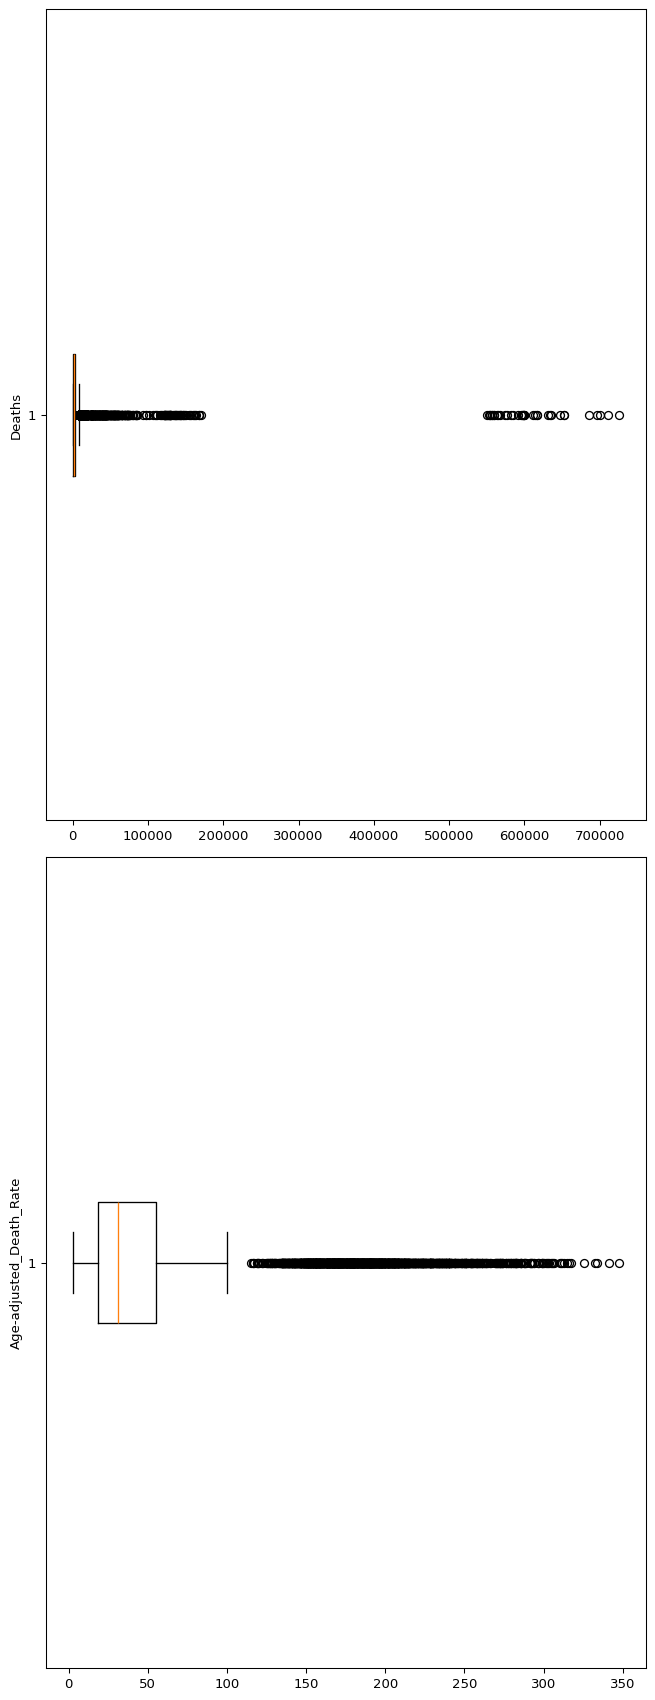

In [ ]:
#get numeric columns only
numeric_col=lcd_no_all.select_dtypes(include='number').columns

#figure of boxplot and size of boxplot
fig,axs=plt.subplots(len(numeric_col),1, figsize=(7,18),dpi=95)

#draw one horizontal boxplot for each column
for i,col in enumerate(numeric_col):
    axs[i].boxplot(lcd_no_all[col],vert=False)#
    axs[i].set_ylabel(col)# set y axis as name of column
plt.tight_layout()#prevent overlapping
#plt.show()# display the figures
plt.savefig("Boxplot quartiles.png")

Send Pre Processing output to Database

In [ ]:
#from geeksforgeeks an cdata software
#send data to postgreSQL database
#import   to connect to PostgreSQL
from sqlalchemy import create_engine

#import postGREsql driver
import psycopg2

#host
host='localhost'

#username
username='postgres'

#password
password='MyPostgreSQL'

#default port
port=5432
  
#database name
database='lcd_db'

#connection string for sqlalchemy
conn_string=f'postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}'

#engine allows  for send and receiving data
engine=create_engine(conn_string)

#save processed data to database
lcd_no_all.to_sql('lcd_no_all',engine,if_exists='replace',index=False)

880

Retrieve Pre Processing output from Database

In [328]:

#load pre processing output from  postgreSQL
lcd_no_all=pd.read_sql("SELECT * FROM lcd_no_all",engine)





Data analysis

In [ ]:
#latest date in dataset
lcd_no_all['Year'].max()

'2017'

In [ ]:
#oldest date in dataset
lcd_no_all['Year'].min()


'1999'

The different causes of death and Number of Ocurrances

In [ ]:
#cause name,number of occurances
lcd_no_all['Cause_Name'].value_counts().head(10)

Cause_Name
Unintentional injuries     988
All causes                 988
Alzheimer's disease        988
Stroke                     988
CLRD                       988
Diabetes                   988
Heart disease              988
Influenza and pneumonia    988
Suicide                    988
Cancer                     988
Name: count, dtype: int64

State Deaths without national deaths included

In [ ]:
# remove 'All causes' for more concise results
lcd_no_all = lcd[lcd['Cause_Name'] != 'All causes']
# state deaths seperated from United State national deaths
state_deaths=lcd_no_all[lcd_no_all['State']!='United States']
print(state_deaths)


       Year              Cause_Name          State  Deaths  \
1      2017  Unintentional injuries        Alabama    2703   
2      2017  Unintentional injuries         Alaska     436   
3      2017  Unintentional injuries        Arizona    4184   
4      2017  Unintentional injuries       Arkansas    1625   
5      2017  Unintentional injuries     California   13840   
...     ...                     ...            ...     ...   
10863  1999          Kidney disease       Virginia    1035   
10864  1999          Kidney disease     Washington     278   
10865  1999          Kidney disease  West Virginia     345   
10866  1999          Kidney disease      Wisconsin     677   
10867  1999          Kidney disease        Wyoming      30   

       Age-adjusted_Death_Rate  
1                         53.8  
2                         63.7  
3                         56.2  
4                         51.8  
5                         33.2  
...                        ...  
10863                   

In [ ]:
# state deaths seperated from United State national deaths occurrences
state_deaths=lcd_no_all[lcd_no_all['State']!='United States']
state_deaths['State'].value_counts()

State
Alabama                 190
Pennsylvania            190
Nevada                  190
New Hampshire           190
New Jersey              190
New Mexico              190
New York                190
North Carolina          190
North Dakota            190
Ohio                    190
Oklahoma                190
Oregon                  190
Rhode Island            190
Montana                 190
South Carolina          190
South Dakota            190
Tennessee               190
Texas                   190
Utah                    190
Vermont                 190
Virginia                190
Washington              190
West Virginia           190
Wisconsin               190
Nebraska                190
Missouri                190
Alaska                  190
Idaho                   190
Arizona                 190
Arkansas                190
California              190
Colorado                190
Connecticut             190
Delaware                190
District of Columbia    190
Florida       

National Deaths without state deaths included

In [ ]:
#dataframe national deaths seperated from state deaths
national_deaths=lcd_no_all[lcd_no_all['State']=='United States']
national_deaths['State'].value_counts().sum()
print(national_deaths)

       Year               Cause_Name          State  Deaths  \
0      2017   Unintentional injuries  United States  169936   
104    2017      Alzheimer's disease  United States  121404   
156    2017                   Stroke  United States  146383   
208    2017                     CLRD  United States  160201   
260    2017                 Diabetes  United States   83564   
...     ...                      ...            ...     ...   
10652  1999            Heart disease  United States  725192   
10705  1999  Influenza and pneumonia  United States   63730   
10757  1999                  Suicide  United States   29199   
10808  1999                   Cancer  United States  549838   
10860  1999           Kidney disease  United States   35525   

       Age-adjusted_Death_Rate  
0                         49.4  
104                       31.0  
156                       37.6  
208                       40.9  
260                       21.5  
...                        ...  
10652       

In [ ]:
#dataframe with state deaths seperated from national deaths
state_no_national=lcd_no_all[lcd_no_all['State']!='United States']
#
state_causes_deaths=state_no_national.groupby(['State','Cause_Name'])['Deaths'].sum().sort_values()
print(state_deaths)

       Year              Cause_Name          State  Deaths  \
1      2017  Unintentional injuries        Alabama    2703   
2      2017  Unintentional injuries         Alaska     436   
3      2017  Unintentional injuries        Arizona    4184   
4      2017  Unintentional injuries       Arkansas    1625   
5      2017  Unintentional injuries     California   13840   
...     ...                     ...            ...     ...   
10863  1999          Kidney disease       Virginia    1035   
10864  1999          Kidney disease     Washington     278   
10865  1999          Kidney disease  West Virginia     345   
10866  1999          Kidney disease      Wisconsin     677   
10867  1999          Kidney disease        Wyoming      30   

       Age-adjusted_Death_Rate  
1                         53.8  
2                         63.7  
3                         56.2  
4                         51.8  
5                         33.2  
...                        ...  
10863                   

In [247]:
#causes of death in the united states and total number of deaths
usa_death_causes=national_deaths.groupby('Cause_Name')['Deaths'].sum().sort_values()
print(usa_death_causes)

Cause_Name
Suicide                      697016
Kidney disease               858613
Influenza and pneumonia     1094641
Diabetes                    1399943
Alzheimer's disease         1494816
Unintentional injuries      2347820
CLRD                        2594927
Stroke                      2726523
Cancer                     10843644
Heart disease              12222640
Name: Deaths, dtype: int64


In [ ]:
#Number of occurances United states (national deaths)
national_deaths['State'].value_counts()


State
United States    190
Name: count, dtype: int64

In [ ]:
#dataframe with only number of deaths in each state
state_deaths_total=state_no_national.groupby(['State','Cause_Name'])['Deaths'].sum().sort_values()
print(state_deaths_total)

State                 Cause_Name             
District of Columbia  Suicide                        690
Alaska                Kidney disease                 783
Vermont               Kidney disease                 892
Alaska                Influenza and pneumonia        999
Wyoming               Kidney disease                1173
                                                  ...   
Florida               Cancer                      782683
                      Heart disease               862602
New York              Heart disease               939172
California            Cancer                     1062235
                      Heart disease              1204573
Name: Deaths, Length: 510, dtype: int64


Insight 1: There is no correlation between number of deaths by a specific cause and age adjusted death rate the United States of America. 

Correlation of Age and Age Adjusted Death

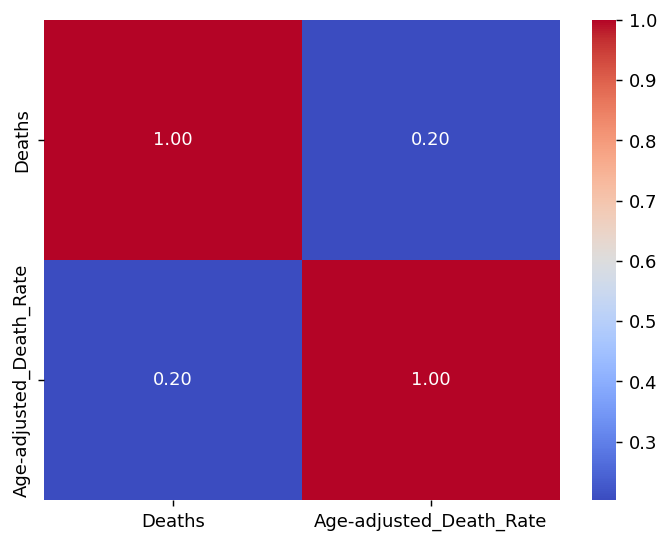

In [ ]:
#insight 1 visualisation
#correlation between death and age adjusted deaths
corr=lcd_no_all[['Deaths','Age-adjusted_Death_Rate']].corr()

plt.figure(dpi=130)#create heatmap figure

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')#draw heatmap

#save graph
plt.savefig("correlation between death and age adjusted deaths.png")

plt.show()

Deaths vs Age-adjusted_Death_Rate"

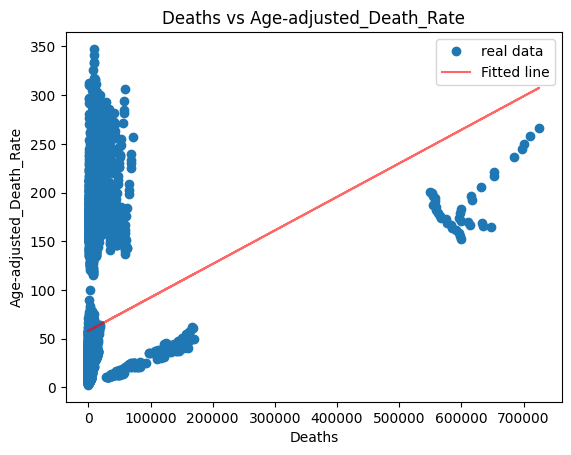

In [ ]:
#Insight 1 visualisation
#visualise actual data points
plt.plot(lcd_no_all['Deaths'],lcd_no_all['Age-adjusted_Death_Rate'],'o',label='real data')

#lineear regression of Age-adjusted_Death_Rate per deaths
slope,intercept,r_value,p_value,std_error=stats.linregress(lcd_no_all['Deaths'],lcd_no_all['Age-adjusted_Death_Rate'])
#visualise the predictions
plt.plot(lcd_no_all['Deaths'], intercept + slope * lcd_no_all['Deaths'],'r',label='Fitted line',alpha=0.6)


#add legend age and age adjusted death
plt.legend()
plt.xlabel("Deaths")
plt.ylabel("Age-adjusted_Death_Rate")
plt.title("Deaths vs Age-adjusted_Death_Rate")

#save graph
plt.savefig("Deaths vs Age_adjusted_Death_Rate.png")

#display graph
plt.show()


Leading cause of death for every year(Applies to insight 2 and 3)

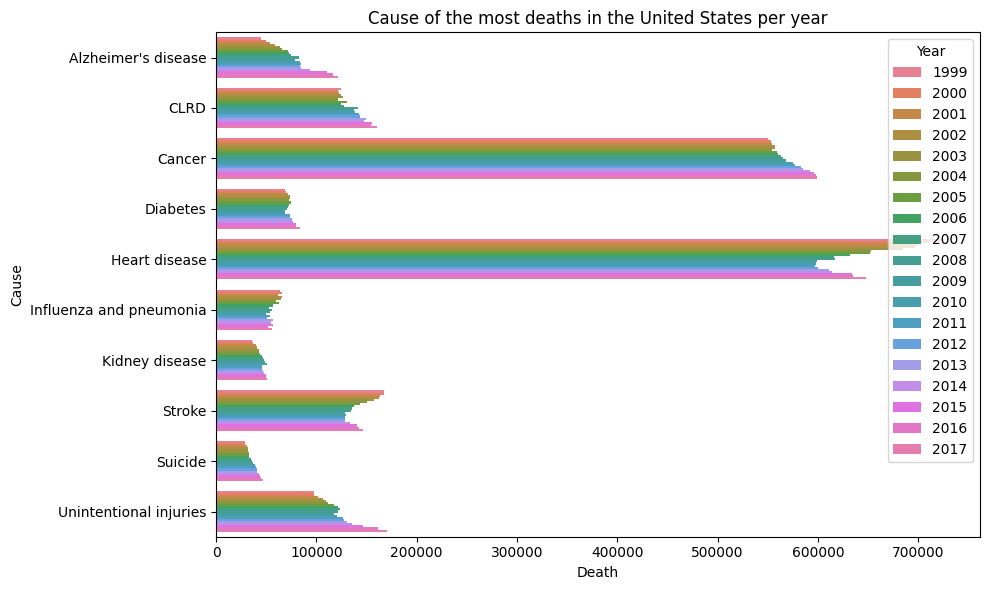

<Figure size 640x480 with 0 Axes>

In [276]:
#get the national death sorted by year and cause name,get number of deaths,and turns index back into columns
usa_death_causes_year=national_deaths.groupby(['Year','Cause_Name'])['Deaths'].sum().reset_index()
#figure size
plt.figure(figsize=(10,6))
#number of deaths is x,causes is y, each year as a different color, seperate bars by color
sns.barplot(data=usa_death_causes_year,x='Deaths',y='Cause_Name',hue='Year',dodge=True)
plt.title("Cause of the most deaths in the United States per year")#title of graph


plt.xlabel("Death")#title of x axis

plt.ylabel("Cause")#title of y axis

plt.tight_layout()#prevents clipping

plt.show()#display graph

plt.savefig("The cause of the most deaths in the US by year.png")#save graph



Insight 2: 
The causes of death “Heart disease” and “Cancer” have throughout the years from 1997 to 2017 consistently been the leading cause for the most deaths that year in the United States of America.

Percentage of deaths by cause in the United States

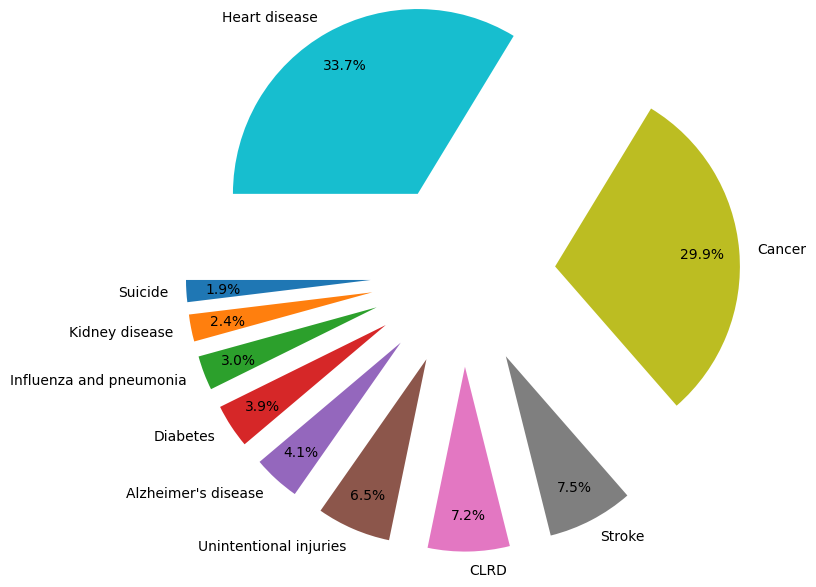

In [334]:

#figure size
plt.figure(figsize=(10,6))

#define exlplode
explode=([0.5]*len(usa_death_causes))
#design piechart
plt.pie(x=usa_death_causes.values,labels=usa_death_causes.index,
        autopct='%1.1f%%',#percentage 1 decimal place
        pctdistance=0.8,labeldistance=1.1,#distance of labels and percentage from label
        startangle=180,explode=explode)# angle of chart and split chart
#color for each cause
colors=sns.color_palette('pastel',len(usa_death_causes))

plt.savefig("Percentage of deaths by cause in the United States.png")# save graph
plt.show()#display chart





Insight 3: 
There is a visible trend of increase, decrease and relative stability  in the number of deaths for different causes of death.

    Trend of Total Deaths by the most common Causes

Index(['Heart disease', 'Cancer', 'Stroke', 'CLRD', 'Unintentional injuries'], dtype='object', name='Cause_Name')
Cause_Name
Suicide                      697016
Kidney disease               858613
Influenza and pneumonia     1094641
Diabetes                    1399943
Alzheimer's disease         1494816
Unintentional injuries      2347820
CLRD                        2594927
Stroke                      2726523
Cancer                     10843644
Heart disease              12222640
Name: Deaths, dtype: int64
       Year              Cause_Name          State  Deaths  \
0      2017  Unintentional injuries  United States  169936   
1      2017  Unintentional injuries        Alabama    2703   
2      2017  Unintentional injuries         Alaska     436   
3      2017  Unintentional injuries        Arizona    4184   
4      2017  Unintentional injuries       Arkansas    1625   
...     ...                     ...            ...     ...   
10811  1999                  Cancer       Virginia   1

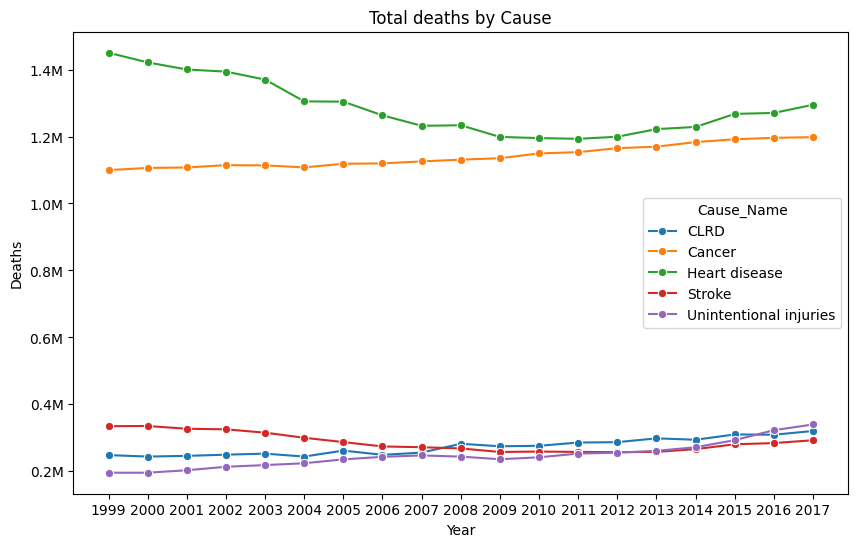

In [340]:
#get total deaths by top cause
top_deaths_cause=lcd_no_all.groupby('Cause_Name')['Deaths'].sum().sort_values(ascending=False).head(5).index
print(top_deaths_cause)

print(usa_death_causes)
#top 5 causes of death
top5_causes=lcd_no_all[lcd_no_all['Cause_Name'].isin(top_deaths_cause)]
print(top5_causes)
#group the top five causes of death by Year cause_name
top_causes=top5_causes.groupby(['Year','Cause_Name'])['Deaths'].sum().reset_index()

#figure size
plt.figure(figsize=(10,6))

#(ascending=False).reset_index()

#plot graph
sns.lineplot(data=top_causes,x='Year',y='Deaths',hue='Cause_Name',marker='o')

#from stack overflow function to get deaths in millions
from matplotlib.ticker import FuncFormatter #import funcformatter
def millions(x,pos):
    return '%1.1fM' % (x * 1e-6)

plt.gca().yaxis.set_major_formatter(FuncFormatter(millions))

plt.xlabel("Year")#title of x axis
plt.ylabel("Deaths")#title of y axis
plt.title("Total deaths by Cause")#graph title


plt.savefig("Trend of Total Deaths and main Causes from 1997 to 2017.png")#display graph
plt.show()#display graph

Insight 4:
There is a difference in the cause of most deaths in the four regions of the United States of America “northeast, midwest, west and south".

Leading Cause of Death by sub regions of the US

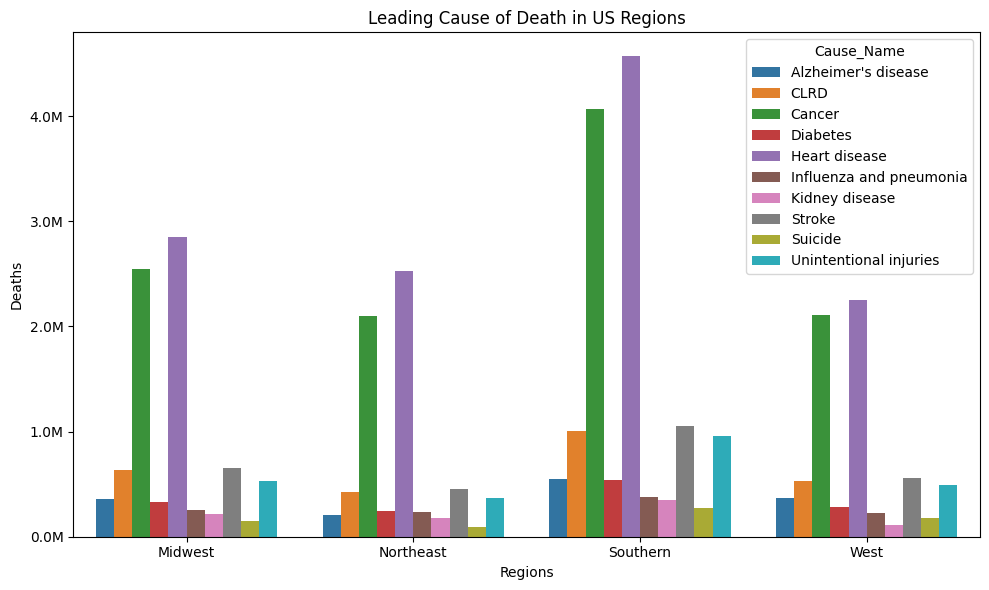

In [ ]:
#copy of state no national
state_no_national_c=state_no_national.copy()
northeast=['Connecticut','Maine','Massachusetts','New Hampshire','Rhode Island','New Jersey','New York','Pennsylvania']
midwest=['Illinois','Indiana','Michigan','Ohio','Wisconsin',
         'Iowa','Kansas','Minnesota','Missouri','Nebraska','North Dakota','South Dakota']
south=['Delaware','District of Columbia','Florida','Georgia','Maryland','North Carolina',
       'South Carolina','Virginia','West Virginia','Kentucky','Tennessee','Mississippi','Alabama',
        'Arkansas','Louisiana','Oklahoma','Texas']
west=['Arizona','Colorado','Idaho','Montana','Nevada','New Mexico','Utah','Wyoming',
      'Alaska','California','Hawaii','Oregon','Washington']

#empty dictionary for sub regions
regions={}

#assign northeast states to northeast subregion
for x in northeast:
    regions[x]='Northeast'

#assign midwest states to midwest subregion
for x in midwest:
    regions[x]='Midwest'
#assign western states to west subregion
for x in west:
    regions[x]='West'
#assign southern states to south subregion
for x in south:
    regions[x]='Southern'
#map the state to its correct subregion
state_no_national_c['Regions']=state_no_national_c['State'].map(regions)

#appends subregions to empty dictionary
regions_deaths=state_no_national_c.groupby(['Regions','Cause_Name'])['Deaths'].sum().reset_index()

#graph size
plt.figure(figsize=(10,6))

#plot grouped bar chart
sns.barplot(data=regions_deaths,x='Regions',y='Deaths',hue='Cause_Name')

#from stackoverflow
#showing deaths in millions
from matplotlib.ticker import FuncFormatter#import funcformatter
#function for formatting deaths to be in millions
def millions(x,pos):
    return '%1.1fM' % (x * 1e-6)

#apply function
plt.gca().yaxis.set_major_formatter(FuncFormatter(millions))

plt.xlabel("Regions")#x axis name
plt.ylabel("Deaths")#y axis name
plt.title("Leading Cause of Death in US Regions")#title of graph
plt.tight_layout()# prevent clipping

#save graph
plt.savefig("Leading Cause of Death in US sub Regions.png")

#display graph
plt.show()

